# **Week 5 作業：MNIST 手寫數字辨識**

## 四層神經元

In [1]:
N1 = 11
N2 = 73
N3 = 52
N4 = 61

## 套件讀入

Gradio支持多種類型的輸入數據（文本、圖片、視頻等），並提供了各種用於定制和配置界面的選項

In [2]:
!pip install gradio

In [46]:
#用於將Matplotlib圖形嵌入到Jupyter Notebook或Jupyter Lab中的輸出中
%matplotlib inline

import numpy as np #數值計算和數據操作
import matplotlib.pyplot as plt #繪製圖形

# 神經網路
from tensorflow.keras.datasets import mnist #從TensorFlow庫的keras模塊中導入了MNIST數據集(手寫數字圖片數據集)
from tensorflow.keras.utils import to_categorical #類別或資料轉換成ine hot encoding(熱編碼)
from tensorflow.keras.models import Sequential #構建順序模型，空白的神經網路
from tensorflow.keras.layers import Dense #DNN
from tensorflow.keras.optimizers import SGD #SGD（隨機梯度下降）優化器，隨機抽取題目

# 互動設計用
from ipywidgets import interact_manual #手動觸發的互動式小工具
# 神速打造 web app 的 Gradio
import gradio as gr

## 讀入 MNIST 數據庫

MNIST 是有一堆 0-9 的整數手寫數字圖庫，每個圖片都是一個28x28像素的灰度圖，顯示了手寫的單個數字。共有 6 萬筆訓練資料, 1 萬筆測試資料。

它是 "Modified" 版的 NIST 數據庫, 由 LeCun, Cortes, 及 Burges 等人做的。

MNIST 可以說是 Deep Learning 最有名的範例, 它被 Deep Learning 大師 Hinton 稱為「機器學習的果蠅」。

### 由 Keras 讀入 MNIST

- **mnist.load_data():** 是從TensorFlow.keras.datasets中導入的mnist，以此提供了一個方便的函數load_data()，用於從MNIST數據集中加載數據。該函數將返回兩個元組，分別包含訓練數據和測試數據。

- **(x_train, y_train), (x_test, y_test) :** 將load_data()函數返回的兩個元組分別解包為四個變量。
  
  - x_train是訓練數據的特徵
  - y_train是訓練數據的標籤
  - x_test是測試數據的特徵
  - y_test是測試數據的標籤

In [47]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

確認訓練資料和測試資料總筆數（長度）

In [48]:
print(f'訓練資料總筆數為 {len(x_train)} 筆資料')
print(f'測試資料總筆數為 {len(x_test)} 筆資料')

訓練資料總筆數為 60000 筆資料
測試資料總筆數為 10000 筆資料


### 數據庫的內容確認

每筆輸入 (x) 就是一個手寫的 0-9 中一個數字的圖檔, 大小為 28x28。

輸出 (y) 則是該手寫圖（x）對應的 標籤＝「正確答案」。

In [49]:
def show_xy(n=0):
    ax = plt.gca() # 創建了一個子圖，確保圖形在顯示時具有一致的環境設定
    X = x_train[n] # 從訓練數據集中獲取指定索引第n個

    # 用於將 x 軸和 y 軸的刻度清除，讓圖片更加清晰
    plt.xticks([], [])
    plt.yticks([], [])

    # 顯示圖片，X ：圖片數據，cmap='Greys' ：以灰度顏色顯示圖片
    plt.imshow(X, cmap = 'Greys')
    plt.show() #顯示圖片，每次只輸出一個

    # 在顯示圖片後打印出相應的標籤
    print(f'本資料 y 給定的答案為: {y_train[n]}')

In [50]:
# 創建一個互動小工具，可以以互動拖拉方式，指定圖片的索引（訓練資料集包含了 60000 張圖）
interact_manual(show_xy, n=(0,59999));

interactive(children=(IntSlider(value=0, description='n', max=59999), Button(description='Run Interact', style…

顯示訓練數據集中指定索引的圖片數據

電腦處理的不是圖片，而是由數字拼湊的數據

In [51]:
def show_data(n = 0):
    X = x_train[n]
    print(X)

In [52]:
interact_manual(show_data, n=(0,59999));

interactive(children=(IntSlider(value=0, description='n', max=59999), Button(description='Run Interact', style…

## 簡化數據

### 整理輸入格式

原先的圖片數據是每個 28x28 的矩陣 (array), 但標準神經網路只吃一維數值, 用 reshape 調校成 28x28=784 長的向量。

讓電腦只需讀取0~1之間的值，所以除以255

In [10]:
x_train = x_train.reshape(60000, 784)/255
x_test = x_test.reshape(10000, 784)/255

### 整理輸出格式

1-hot enconding 表示

- 處理類別型數據：對於分類問題，標籤通常是類別型數據，而不是連續型數據。
- 避免假設順序：將類別表示為整數會導致模型假設類別之間存在順序關係，但在許多情況下這是不合理的。

而我們將y（數據的標籤）轉換為1-hot enconding，以避免這些label有順序性或其他的混淆。

In [11]:
# 未整理過的
n = 2 #第2筆
y_train[n] #輸出他的維度

4

In [12]:
y_train.shape # 查看訓練數據集的目標標籤（y_train）的形狀

# to_categorical 函數用來將整數型的類別標籤轉換為 one-hot encoded 的格式
# 在MNIST數據集中，共有10個類別（0到9）
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [13]:
# 整理過的: 1-hot enconding
n = 2 #第2筆
y_train[n] #輸出他的維度

array([0., 0., 0., 0., 1., 0., 0., 0., 0., 0.], dtype=float32)

## 建造神經元

函數是:

$$\hat{f} \colon \mathbb{R}^{784} \to \mathbb{R}^{10}$$

### 神經網路架構

### 輸入

Sequential()是Keras 的一種模型套件，用於創建序列模型（線性堆疊的神經網絡）。

In [14]:
# 建造一個空的神經網路
model = Sequential()

TensorFlow 在構建神經網絡時，需要知道**每一層的輸入形狀（input shape）**，以便在創建模型時初始化權重矩陣。

而在最初隱藏層時，因為在最初的隱藏層之前並沒有其他層來決定輸入形狀，因此我們要自行設定，因為 TensorFlow 無法自動推斷它。

用 add 去個別加入每一層的神經網路, 從第一個隱藏層開始

- N1 是第一個(隱藏層)神經元

- 784（一維圖片數值）是初始的features

In [15]:
model.add(Dense(N1, input_dim=784, activation='relu'))

在大多情況下，特別是在線性層（Dense layer）中，**輸入形狀是由前一層的神經元**數目決定的。
就不需要再設定input_dim了！

In [16]:
model.add(Dense(N2, activation='relu'))

In [17]:
model.add(Dense(N3, activation='relu'))

In [18]:
model.add(Dense(N4, activation='relu'))

### 輸出

輸出有 10 個數字類別（1-hot enconding）, 所以輸出層的神經元是 10 個

並且再用 `softmax` 把 $(y_1, y_2, \ldots, y_{10})$ 轉成 $\sum_{i=1}^{10} y_i = 1$



In [19]:
model.add(Dense(10, activation='softmax'))

In [20]:
# 刪掉最後一層
#model.pop()

### 組裝

In [21]:
# 邊訓練邊查看結果
metrics=['accuracy']

在神經網絡建立完成後，進行編譯（compile）並設置一些重要的參數：

*   **損失函數（Loss Function）：**用於衡量模型預測與實際標籤之間的差異，以判斷正確率。
  *  均方誤差（Mean Squared Error, MSE）通常是一個合適處理回歸問題的損失函數。
*   **優化器（Optimizer）：**以更新權重去最小化損失函數
  *  SGD（隨機梯度下降）是一種常見的優化器
*   **學習率（Learning Rate）：**決定每次參數更新的步長。
  *  學習率太大：可能會導致振盪
  *  學習率太小：可能會導致收斂速度過慢

## 測試集

learning_rate=0.088

In [22]:
model.compile(loss='mse', optimizer=SGD(learning_rate=0.088), metrics=['accuracy'])

###檢查神經元模型

查看 model 的 summary

In [23]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 11)                8635      
                                                                 
 dense_1 (Dense)             (None, 73)                876       
                                                                 
 dense_2 (Dense)             (None, 52)                3848      
                                                                 
 dense_3 (Dense)             (None, 61)                3233      
                                                                 
 dense_4 (Dense)             (None, 10)                620       
                                                                 
Total params: 17212 (67.23 KB)
Trainable params: 17212 (67.23 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


###訓練神經網路

使用 Keras 中的 fit() 方法來訓練神經網絡模型

- batch_size：這表示每次訓練時使用的批量(同時處理)大小
> 要求一次性處理大量的數據，導致計算量過大，並可能導致內存不足等問題
- epochs：這表示訓練的 epoch 數量，即模型將對整個訓練數據集進行多少次完整的訓練
> 如果訓練次數過多會變成 overfitting，導致在測試數據上的性能下降

在每個 epoch 結束時，Keras 將計算並顯示模型在訓練數據集上的損失和準確率，以便追蹤模型的訓練進度和效果。

發現 overfitting 通常涉及觀察模型在訓練集和驗證集上的表現：

- 訓練和驗證損失：訓練損失持續下降，但驗證損失開始上升
- 訓練和驗證準確率：訓練準確率持續提高，但驗證準確率開始下降

#### ver1
- 批次輸入=100
- 訓練次數=10

- 初始loss 最低為 0.0167
- 初始accuracy最高為 0.8911

In [24]:
#model.fit(x_train, y_train, batch_size=100, epochs=10)

Epoch 1/10

600/600 [==============================] - 3s 3ms/step - loss: 0.0896 - accuracy: 0.1353

Epoch 2/10

600/600 [==============================] - 2s 4ms/step - loss: 0.0879 - accuracy: 0.1725

Epoch 3/10

600/600 [==============================] - 3s 6ms/step - loss: 0.0802 - accuracy: 0.2876

Epoch 4/10

600/600 [==============================] - 5s 8ms/step - loss: 0.0635 - accuracy: 0.5419

Epoch 5/10

600/600 [==============================] - 4s 7ms/step - loss: 0.0420 - accuracy: 0.7092

Epoch 6/10

600/600 [==============================] - 4s 6ms/step - loss: 0.0291 - accuracy: 0.8107

Epoch 7/10

600/600 [==============================] - 3s 5ms/step - loss: 0.0229 - accuracy: 0.8508

Epoch 8/10

600/600 [==============================] - 2s 3ms/step - loss: 0.0198 - accuracy: 0.8718

Epoch 9/10

600/600 [==============================] - 2s 3ms/step - loss: 0.0179 - accuracy: 0.8839

Epoch 10/10

600/600 [==============================] - 2s 3ms/step - loss: 0.0167 - accuracy: 0.8911

####Ver2

- batch_size =100
- 「增加」epochs=15


accuracy增加到了90以上，最高為0.9115

loss下降蠻多的，最低為0.0136

In [25]:
#model.fit(x_train, y_train, batch_size=100, epochs=15)

Epoch 1/15

600/600 [==============================] - 3s 3ms/step - loss: 0.0893 - accuracy: 0.1668

Epoch 2/15

600/600 [==============================] - 2s 4ms/step - loss: 0.0846 - accuracy: 0.2146

Epoch 3/15

600/600 [==============================] - 3s 5ms/step - loss: 0.0787 - accuracy: 0.3411

Epoch 4/15

600/600 [==============================] - 5s 8ms/step - loss: 0.0653 - accuracy: 0.5622

Epoch 5/15

600/600 [==============================] - 3s 5ms/step - loss: 0.0375 - accuracy: 0.7745

Epoch 6/15

600/600 [==============================] - 4s 6ms/step - loss: 0.0252 - accuracy: 0.8387

Epoch 7/15

600/600 [==============================] - 5s 8ms/step - loss: 0.0210 - accuracy: 0.8645

Epoch 8/15

600/600 [==============================] - 2s 3ms/step - loss: 0.0188 - accuracy: 0.8769

Epoch 9/15

600/600 [==============================] - 2s 3ms/step - loss: 0.0175 - accuracy: 0.8864

Epoch 10/15

600/600 [==============================] - 2s 3ms/step - loss: 0.0165 - accuracy: 0.8932

Epoch 11/15

600/600 [==============================] - 2s 3ms/step - loss: 0.0157 - accuracy: 0.8973

Epoch 12/15

600/600 [==============================] - 2s 3ms/step - loss: 0.0151 - accuracy: 0.9017

Epoch 13/15

600/600 [==============================] - 2s 3ms/step - loss: 0.0145 - accuracy: 0.9056

Epoch 14/15

600/600 [==============================] - 3s 4ms/step - loss: 0.0141 - accuracy: 0.9083

Epoch 15/15

600/600 [==============================] - 2s 3ms/step - loss: 0.0136 - accuracy: 0.9115

<keras.src.callbacks.History at 0x7c195fdf3760>


####Ver3

- batch_size =100
- 「增加」epochs=25


accuracy有稍微增加，最高到0.9259

loss 反而增加了一些，可能是因為epochs增加比較多的關係

In [26]:
#model.fit(x_train, y_train, batch_size=100, epochs=25)

Epoch 1/25


600/600 [==============================] - 3s 3ms/step - loss: 0.0898 - accuracy: 0.1178

Epoch 2/25

600/600 [==============================] - 4s 7ms/step - loss: 0.0891 - accuracy: 0.2059

Epoch 3/25

600/600 [==============================] - 3s 5ms/step - loss: 0.0871 - accuracy: 0.2462

Epoch 4/25

600/600 [==============================] - 4s 7ms/step - loss: 0.0784 - accuracy: 0.3314

Epoch 5/25

600/600 [==============================] - 5s 8ms/step - loss: 0.0642 - accuracy: 0.5445

Epoch 6/25

600/600 [==============================] - 4s 7ms/step - loss: 0.0430 - accuracy: 0.7225

Epoch 7/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0264 - accuracy: 0.8341

Epoch 8/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0207 - accuracy: 0.8669

Epoch 9/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0185 - accuracy: 0.8803

Epoch 10/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0172 - accuracy: 0.8881

Epoch 11/25

600/600 [==============================] - 2s 4ms/step - loss: 0.0163 - accuracy: 0.8937

Epoch 12/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0156 - accuracy: 0.8983

Epoch 13/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0150 - accuracy: 0.9025

Epoch 14/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0145 - accuracy: 0.9058

Epoch 15/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0141 - accuracy: 0.9088

Epoch 16/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0138 - accuracy: 0.9109

Epoch 17/25

600/600 [==============================] - 5s 8ms/step - loss: 0.0135 - accuracy: 0.9130

Epoch 18/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0132 - accuracy: 0.9151

Epoch 19/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0129 - accuracy: 0.9174

Epoch 20/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0126 - accuracy: 0.9195

Epoch 21/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0124 - accuracy: 0.9200

Epoch 22/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0121 - accuracy: 0.9219

Epoch 23/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0119 - accuracy: 0.9239

Epoch 24/25

600/600 [==============================] - 3s 4ms/step - loss: 0.0117 - accuracy: 0.9248

Epoch 25/25

600/600 [==============================] - 2s 3ms/step - loss: 0.0115 - accuracy: 0.9259

<keras.src.callbacks.History at 0x78475b8e8910>

####Ver4
- 「增加」batch_size =150
- 「減少」epochs=20

跟Ver1.2相比（batch_size=150, epochs=15），loss: 0.0136 - accuracy: 0.9115

結果並沒有變得比較好。

accuracy減少蠻多的，最高為0.8723

loss甚至也比較多，因為batch_size比教多一點

-->應該要著重在調整epochs

In [27]:
#model.fit(x_train, y_train, batch_size=150, epochs=15)

Epoch 1/15

400/400 [==============================] - 4s 6ms/step - loss: 0.0899 - accuracy: 0.1444

Epoch 2/15

400/400 [==============================] - 3s 7ms/step - loss: 0.0896 - accuracy: 0.2384

Epoch 3/15

400/400 [==============================] - 2s 6ms/step - loss: 0.0890 - accuracy: 0.2883

Epoch 4/15

400/400 [==============================] - 3s 8ms/step - loss: 0.0876 - accuracy: 0.2988

Epoch 5/15

400/400 [==============================] - 2s 5ms/step - loss: 0.0836 - accuracy: 0.3121

Epoch 6/15

400/400 [==============================] - 3s 8ms/step - loss: 0.0765 - accuracy: 0.3791

Epoch 7/15

400/400 [==============================] - 3s 7ms/step - loss: 0.0658 - accuracy: 0.4627

Epoch 8/15

400/400 [==============================] - 3s 6ms/step - loss: 0.0537 - accuracy: 0.5971

Epoch 9/15

400/400 [==============================] - 2s 5ms/step - loss: 0.0419 - accuracy: 0.7207

Epoch 10/15

400/400 [==============================] - 2s 5ms/step - loss: 0.0329 - accuracy: 0.7827

Epoch 11/15

400/400 [==============================] - 3s 7ms/step - loss: 0.0276 - accuracy: 0.8169

Epoch 12/15

400/400 [==============================] - 2s 6ms/step - loss: 0.0244 - accuracy: 0.8384

Epoch 13/15

400/400 [==============================] - 2s 5ms/step - loss: 0.0222 - accuracy: 0.8538

Epoch 14/15

400/400 [==============================] - 3s 7ms/step - loss: 0.0207 - accuracy: 0.8644

Epoch 15/15

400/400 [==============================] - 2s 5ms/step - loss: 0.0195 - accuracy: 0.8723

<keras.src.callbacks.History at 0x7be201a9cd90>

####Ver5（目前最好）
- 「減少」batch_size =100
- 「增加」epochs=30

accuracy有在增加，最高為0.9317

loss 意外地減少蠻多的，甚至比Ver2少，最低為0.0107

In [28]:
#model.fit(x_train, y_train, batch_size=100, epochs=30)

Epoch 1/30

600/600 [==============================] - 3s 4ms/step - loss: 0.0898 - accuracy: 0.1228

Epoch 2/30

600/600 [==============================] - 3s 5ms/step - loss: 0.0888 - accuracy: 0.2068

Epoch 3/30

600/600 [==============================] - 3s 5ms/step - loss: 0.0856 - accuracy: 0.2972

Epoch 4/30

600/600 [==============================] - 4s 7ms/step - loss: 0.0754 - accuracy: 0.4420

Epoch 5/30

600/600 [==============================] - 5s 8ms/step - loss: 0.0578 - accuracy: 0.6081

Epoch 6/30

600/600 [==============================] - 4s 6ms/step - loss: 0.0399 - accuracy: 0.7378

Epoch 7/30

600/600 [==============================] - 3s 5ms/step - loss: 0.0311 - accuracy: 0.7878

Epoch 8/30

600/600 [==============================] - 2s 4ms/step - loss: 0.0260 - accuracy: 0.8276

Epoch 9/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0225 - accuracy: 0.8509

Epoch 10/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0205 - accuracy: 0.8643

Epoch 11/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0190 - accuracy: 0.8745

Epoch 12/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0178 - accuracy: 0.8832

Epoch 13/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0168 - accuracy: 0.8902

Epoch 14/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0159 - accuracy: 0.8959

Epoch 15/30

600/600 [==============================] - 3s 4ms/step - loss: 0.0151 - accuracy: 0.9014

Epoch 16/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0146 - accuracy: 0.9052

Epoch 17/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0140 - accuracy: 0.9094

Epoch 18/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0136 - accuracy: 0.9123

Epoch 19/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0131 - accuracy: 0.9155

Epoch 20/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0128 - accuracy: 0.9175

Epoch 21/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0125 - accuracy: 0.9199

Epoch 22/30

600/600 [==============================] - 3s 4ms/step - loss: 0.0122 - accuracy: 0.9211

Epoch 23/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0120 - accuracy: 0.9235

Epoch 24/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0117 - accuracy: 0.9247

Epoch 25/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0115 - accuracy: 0.9261

Epoch 26/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0113 - accuracy: 0.9272

Epoch 27/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0111 - accuracy: 0.9284

Epoch 28/30

600/600 [==============================] - 2s 4ms/step - loss: 0.0109 - accuracy: 0.9297

Epoch 29/30

600/600 [==============================] - 2s 4ms/step - loss: 0.0108 - accuracy: 0.9304

Epoch 30/30

600/600 [==============================] - 2s 3ms/step - loss: 0.0107 - accuracy: 0.9317

<keras.src.callbacks.History at 0x7d86b25d2890>

####Ver6
- batch_size =100
- 「增加」epochs=35

epochs有點調太高，成果比上一次差

accuracy減少了，最高0.9292

loss 沒有升很多，最低0.0109

In [29]:
#model.fit(x_train, y_train, batch_size=100, epochs=35)

Epoch 1/35

600/600 [==============================] - 3s 4ms/step - loss: 0.0898 - accuracy: 0.1308

Epoch 2/35

600/600 [==============================] - 3s 5ms/step - loss: 0.0883 - accuracy: 0.1907

Epoch 3/35

600/600 [==============================] - 4s 6ms/step - loss: 0.0828 - accuracy: 0.2844

Epoch 4/35

600/600 [==============================] - 4s 6ms/step - loss: 0.0750 - accuracy: 0.4308

Epoch 5/35

600/600 [==============================] - 5s 8ms/step - loss: 0.0571 - accuracy: 0.6105

Epoch 6/35

600/600 [==============================] - 4s 7ms/step - loss: 0.0349 - accuracy: 0.7788

Epoch 7/35

600/600 [==============================] - 3s 4ms/step - loss: 0.0259 - accuracy: 0.8317

Epoch 8/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0226 - accuracy: 0.8517

Epoch 9/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0207 - accuracy: 0.8636

Epoch 10/35

600/600 [==============================] - 2s 4ms/step - loss: 0.0193 - accuracy: 0.8725

Epoch 11/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0184 - accuracy: 0.8791

Epoch 12/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0176 - accuracy: 0.8848

Epoch 13/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0169 - accuracy: 0.8902

Epoch 14/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0164 - accuracy: 0.8928

Epoch 15/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0159 - accuracy: 0.8957

Epoch 16/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0155 - accuracy: 0.8988

Epoch 17/35

600/600 [==============================] - 2s 4ms/step - loss: 0.0151 - accuracy: 0.9018

Epoch 18/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0148 - accuracy: 0.9038

Epoch 19/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0144 - accuracy: 0.9056

Epoch 20/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0141 - accuracy: 0.9084

Epoch 21/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0138 - accuracy: 0.9105

Epoch 22/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0136 - accuracy: 0.9122

Epoch 23/35

600/600 [==============================] - 2s 4ms/step - loss: 0.0133 - accuracy: 0.9141

Epoch 24/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0130 - accuracy: 0.9150

Epoch 25/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0128 - accuracy: 0.9175

Epoch 26/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0125 - accuracy: 0.9191

Epoch 27/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0123 - accuracy: 0.9205

Epoch 28/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0121 - accuracy: 0.9219

Epoch 29/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0119 - accuracy: 0.9233

Epoch 30/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0117 - accuracy: 0.9247

Epoch 31/35

600/600 [==============================] - 2s 4ms/step - loss: 0.0116 - accuracy: 0.9255

Epoch 32/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0114 - accuracy: 0.9272

Epoch 33/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0112 - accuracy: 0.9277

Epoch 34/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0111 - accuracy: 0.9284

Epoch 35/35

600/600 [==============================] - 2s 3ms/step - loss: 0.0109 - accuracy: 0.9292

<keras.src.callbacks.History at 0x7c54dc02ae60>

####Ver7
- 「增加」batch_size =110
- 「減少」epochs=30



accuracy增加了，最高0.9315

loss 降了一點點，最低0.0106

In [30]:
# model.fit(x_train, y_train, batch_size=110, epochs=30)

Epoch 1/30

546/546 [==============================] - 3s 3ms/step - loss: 0.0897 - accuracy: 0.1388

Epoch 2/30

546/546 [==============================] - 2s 4ms/step - loss: 0.0889 - accuracy: 0.1758

Epoch 3/30

546/546 [==============================] - 4s 8ms/step - loss: 0.0866 - accuracy: 0.2404

Epoch 4/30

546/546 [==============================] - 4s 6ms/step - loss: 0.0817 - accuracy: 0.3343

Epoch 5/30

546/546 [==============================] - 4s 7ms/step - loss: 0.0723 - accuracy: 0.4365

Epoch 6/30

546/546 [==============================] - 5s 9ms/step - loss: 0.0547 - accuracy: 0.6377

Epoch 7/30

546/546 [==============================] - 4s 7ms/step - loss: 0.0350 - accuracy: 0.7769

Epoch 8/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0259 - accuracy: 0.8326

Epoch 9/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0222 - accuracy: 0.8538

Epoch 10/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0201 - accuracy: 0.8677

Epoch 11/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0186 - accuracy: 0.8777

Epoch 12/30

546/546 [==============================] - 3s 5ms/step - loss: 0.0175 - accuracy: 0.8852

Epoch 13/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0165 - accuracy: 0.8914

Epoch 14/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0158 - accuracy: 0.8968

Epoch 15/30

546/546 [==============================] - 2s 4ms/step - loss: 0.0151 - accuracy: 0.9018

Epoch 16/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0145 - accuracy: 0.9055

Epoch 17/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0140 - accuracy: 0.9086

Epoch 18/30

546/546 [==============================] - 2s 4ms/step - loss: 0.0136 - accuracy: 0.9121

Epoch 19/30

546/546 [==============================] - 2s 4ms/step - loss: 0.0132 - accuracy: 0.9145

Epoch 20/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0128 - accuracy: 0.9173

Epoch 21/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0125 - accuracy: 0.9192

Epoch 22/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0122 - accuracy: 0.9209

Epoch 23/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0119 - accuracy: 0.9221

Epoch 24/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0117 - accuracy: 0.9240

Epoch 25/30

546/546 [==============================] - 2s 4ms/step - loss: 0.0115 - accuracy: 0.9252

Epoch 26/30

546/546 [==============================] - 2s 4ms/step - loss: 0.0113 - accuracy: 0.9267

Epoch 27/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0111 - accuracy: 0.9281

Epoch 28/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0109 - accuracy: 0.9290

Epoch 29/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0108 - accuracy: 0.9300

Epoch 30/30

546/546 [==============================] - 2s 3ms/step - loss: 0.0106 - accuracy: 0.9315

<keras.src.callbacks.History at 0x7e924eacfdf0>

####Ver8
- 「增加」batch_size =115
- 「減少」epochs=30



accuracy下降了，最高0.9260

loss 增加了一點，最低為0.0115

In [31]:
#model.fit(x_train, y_train, batch_size=115, epochs=30)

Epoch 1/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0899 - accuracy: 0.1277

Epoch 2/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0894 - accuracy: 0.1886

Epoch 3/30

522/522 [==============================] - 4s 8ms/step - loss: 0.0883 - accuracy: 0.2181

Epoch 4/30

522/522 [==============================] - 3s 6ms/step - loss: 0.0850 - accuracy: 0.2959

Epoch 5/30

522/522 [==============================] - 4s 7ms/step - loss: 0.0776 - accuracy: 0.4051

Epoch 6/30

522/522 [==============================] - 4s 8ms/step - loss: 0.0682 - accuracy: 0.4933

Epoch 7/30

522/522 [==============================] - 4s 7ms/step - loss: 0.0546 - accuracy: 0.6284

Epoch 8/30

522/522 [==============================] - 2s 5ms/step - loss: 0.0383 - accuracy: 0.7462

Epoch 9/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0292 - accuracy: 0.8097

Epoch 10/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0243 - accuracy: 0.8417

Epoch 11/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0214 - accuracy: 0.8611

Epoch 12/30

522/522 [==============================] - 2s 4ms/step - loss: 0.0195 - accuracy: 0.8734

Epoch 13/30

522/522 [==============================] - 2s 4ms/step - loss: 0.0181 - accuracy: 0.8822

Epoch 14/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0172 - accuracy: 0.8882

Epoch 15/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0164 - accuracy: 0.8938

Epoch 16/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0157 - accuracy: 0.8982

Epoch 17/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0152 - accuracy: 0.9008

Epoch 18/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0147 - accuracy: 0.9047

Epoch 19/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0143 - accuracy: 0.9068

Epoch 20/30

522/522 [==============================] - 2s 4ms/step - loss: 0.0140 - accuracy: 0.9090

Epoch 21/30


522/522 [==============================] - 2s 3ms/step - loss: 0.0136 - accuracy: 0.9121

Epoch 22/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0133 - accuracy: 0.9142

Epoch 23/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0130 - accuracy: 0.9155

Epoch 24/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0128 - accuracy: 0.9180

Epoch 25/30

522/522 [==============================] - 1s 3ms/step - loss: 0.0125 - accuracy: 0.9193

Epoch 26/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0123 - accuracy: 0.9203

Epoch 27/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0121 - accuracy: 0.9222

Epoch 28/30

522/522 [==============================] - 2s 5ms/step - loss: 0.0119 - accuracy: 0.9236

Epoch 29/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0117 - accuracy: 0.9247

Epoch 30/30

522/522 [==============================] - 2s 3ms/step - loss: 0.0115 - accuracy: 0.9260

<keras.src.callbacks.History at 0x78ae418ffa60>

## 試用結果

#### 最後用 Ver5

>- batch_size =100
>- epochs=30



>accuracy，最高0.9315

>loss，最低0.0106

In [32]:
model.fit(x_train, y_train, batch_size=100, epochs=30)

Epoch 1/30
600/600 [==============================] - 2s 2ms/step - loss: 0.0898 - accuracy: 0.1280
Epoch 2/30
600/600 [==============================] - 3s 6ms/step - loss: 0.0892 - accuracy: 0.2254
Epoch 3/30
600/600 [==============================] - 3s 6ms/step - loss: 0.0873 - accuracy: 0.3105
Epoch 4/30
600/600 [==============================] - 3s 5ms/step - loss: 0.0784 - accuracy: 0.3100
Epoch 5/30
600/600 [==============================] - 3s 5ms/step - loss: 0.0598 - accuracy: 0.5824
Epoch 6/30
600/600 [==============================] - 4s 7ms/step - loss: 0.0366 - accuracy: 0.7685
Epoch 7/30
600/600 [==============================] - 4s 7ms/step - loss: 0.0264 - accuracy: 0.8292
Epoch 8/30
600/600 [==============================] - 3s 4ms/step - loss: 0.0222 - accuracy: 0.8558
Epoch 9/30
600/600 [==============================] - 1s 2ms/step - loss: 0.0195 - accuracy: 0.8723
Epoch 10/30
600/600 [==============================] - 1s 2ms/step - loss: 0.0177 - accuracy: 0.8849

In [33]:
#擷取整個model的 loss和accuracy 的最終結果值
loss, acc = model.evaluate(x_test, y_test)
print(f"測試資料正確率 {acc*100:.2f}%")

313/313 [==============================] - 1s 2ms/step - loss: 0.0108 - accuracy: 0.9309
測試資料正確率 93.09%


- model.predict(x_test)：使用訓練好的模型對測試集 x_test 進行預測，得到預測結果
- np.argmax(..., axis=-1)：對預測結果進行處理，返回概率值最大的類別索引

In [34]:
#對測試集進行預測，並將預測結果轉換為類別標籤
predict = np.argmax(model.predict(x_test), axis=-1)
predict

313/313 [==============================] - 1s 1ms/step


array([7, 2, 1, ..., 4, 5, 6])

將x_test 一維的 784 向量，轉回圖片（28x28 的矩陣）。


In [35]:
def test(n=0):
    plt.imshow(x_test[n].reshape(28,28), cmap='Greys')
    plt.show
    print('神經網路判斷為:', predict[n])

interactive(children=(IntSlider(value=0, description='n', max=9999), Button(description='Run Interact', style=…

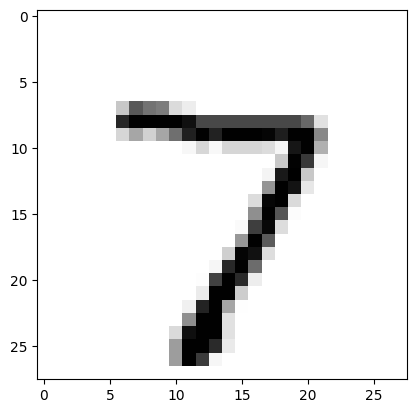

In [36]:
#測試資料有10000筆
interact_manual(test, n=(0, 9999));

#### 給Ver5的神經網路「總評量」

In [37]:
score = model.evaluate(x_test, y_test)

313/313 [==============================] - 1s 2ms/step - loss: 0.0108 - accuracy: 0.9309


In [38]:
print('loss:', score[0])
print('正確率', score[1])

loss: 0.010809740051627159
正確率 0.930899977684021


### 用 Gradio 來展示(未成功)

In [39]:
# def recognize_digit(img):
#   # 將輸入的圖片reshape，以符合模型的輸入要求
#   img = img.reshape((1,784))

#   # 使用模型對調整後的圖像進行預測，得到每個類別的概率分佈
#   #flatten() 函數將結果扁平化
#   prediction = model.predict(img).flatten()

#   #假設數字label有 0 到 9
#   labels = list('0123456789')
#   #返回一個包含每個數字的預測概率的字典
#   return {labels[i]: float(prediction[i]) for i in range(10)}

In [40]:
# import gradio as gr

# image = gr.Sketchpad()
# label = gr.Label(num_top_classes=10)

# interface = gr.Interface(fn=recognize_digit, inputs=image, outputs=label, live=True)

# interface.launch()

In [41]:
# inp = gr.Sketchpad(image_mode='L')

In [42]:
# gr.Interface(fn=recognize_digit, inputs="sketchpad", outputs="label").launch(share=True,debug=True)